## Final fitting of HPK Wlen data
this uses many variations to test the 'diffuse' model

nominal pinhole size is 2mm  
nominal wlens is 350-830nm

This notebook includes all the data:

9nm fwhm is negligible

1. Feb 24 2024 - HPK, all wlens
   1. cold - 160K
   2. old data
      1. veraData/HPK_IR_PDE_feb24_stat_error_only.csv - different processing we believe
      2. HPK_IR_PDE-Feb12_2024-Harry - has angles as well
   3. this was actually reprocessed with different QA data. new data to use is
      1. HPK_PDE_sept24.csv
   4. __only analyzing this data__
2. June/July 2024
   1. various temperatures (-80 to -40)
   2. veraData/angular_scans_VUV_feb2024/*
   3. for next analysis

I think the middle of the junction moves with voltage

looks like you can make a maximum transmission maybe at 600nm

maybe need to do the nested pe, ph fit? compare to the parametrized fit

### Main takeaway
sequential fitting is not working well unless you float FF or let Pesat < 1.0

1. fit 'normally', fixed FF, Psat = 1.0
2. fit and float Psat
3. fit and float FF

In [1]:
fitFlag = "normal"
fitOpt = "diff"
# fitOpt = "l;kj;lkasjfklasjdfkl"
# fitFlag = "floatPsat"
# fitFlag = "floatFF"

Global variables:
	PROJECT_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
	OPTICS_DATA_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	LITERATURE_DATA_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


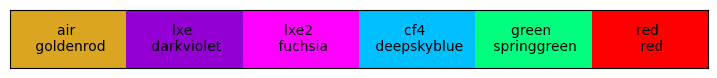

In [2]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *
PrintDAAPSGlobalVariables()

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang
import time
import json

import numpy as np
import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel import OpticsDataLoader as ODL
import PDEModel.MathEquations as ME
import PDEModel.PhotonInfo as PI
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

import FittingTools.PDE_fittingTools as SS
from FittingTools import FittingFunctions as FF

from scipy.interpolate import interp1d

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

---
---
## Parameters shared by everything

In [4]:
# dhSchinke = OpticsData(os.path.join(OPTICS_DATA_PATH, "GoodMerged", "silicon_crystalline_lithoAndSchinke_merged.txt"))


# dhStandard = OpticsData()
# x = np.arange(300, 800, 4)
# phSchinke = PhotonInfo(wlen = x, theta_1 = 0, dataHelper = dhSchinke)
# phStandard = PhotonInfo(wlen = x, theta_1 = 0, dataHelper = dhStandard)

# pnj = PNJ.PNJunction(dp_star = 2, Xpn = 1e3, dw_star= 12e3)
# pnj2 = PNJ.PNJunction(dp_star = 2, Xpn = 2e3, dw_star= 12e3)
# Wscinke = pnj.calcWp(phSchinke)
# Wschink_wider = pnj2.calcWp(phSchinke)
# Wstandard = pnj.calcWp(phStandard)

# plt.plot(x, Wscinke, label = "Schinke")
# plt.plot(x, Wschink_wider, label = "Schinke wider")
# plt.plot(x, Wstandard, label = "Standard")
# plt.legend()

In [5]:
MCFWHM = 4.5 # nm/mm

## VERA SYSTEMATICS
class systematics:
    def __init__(self):
        return

sys1 = systematics()

sys1.mScale = 1.32
sys1.mc_fwhm = 2.0 * MCFWHM * sys1.mScale # in nm
sys1.diodeError = 0.03
# sys1.dh = dh_franta # None
sys1.FF1 = 0.6
sys1.vOffset = 0.05

rel vals: [ 1.          2.00107747  3.03916961  4.22796768  5.73602081  7.36821475
  9.4554152  12.02284971 15.97622144 21.10245216]
0.03755108980794766


array([0.10050373, 0.10777755, 0.13483694, 0.18935681, 0.27041635,
       0.37536116, 0.50249478, 0.65091935, 0.82015913])

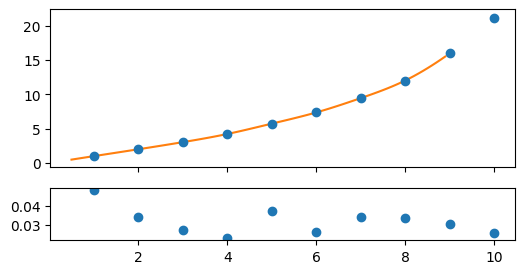

In [6]:
## loading in Harry's NCA error data 
file_path_nca = os.path.join(VERA_DATA_PATH, "NCA_errors/HPK_Q_new.csv")

xV_nca, yV_nca, yE_nca = np.loadtxt(file_path_nca, delimiter=",", unpack=True, skiprows=1, usecols=(0, 1, 2))

yV_nca_relative = yV_nca/min(yV_nca)
yE_nca_relative = yE_nca/yV_nca
print("rel vals:", yV_nca_relative)
finterp_nca = interp1d(xV_nca, yV_nca_relative, kind = "cubic", fill_value = "extrapolate")
finterp_ncaError = interp1d(xV_nca, yE_nca_relative, kind = "cubic", fill_value = "extrapolate")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=1, figsize = (6, 3), height_ratios=[3, 1])
ax1.errorbar(xV_nca, yV_nca_relative, yerr=10*yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
xfurther = np.arange(0.5, 9, 0.1)
ax1.plot(xfurther, finterp_nca(xfurther), label = "Interpolated")

ax2.plot(xV_nca, yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
# ax2.plot(xfurther, finterp_ncaError(xfurther), label = "Interpolated")

def getClosestNCAError(voltage):
    amin = np.argmin(np.abs(xV_nca - voltage))
    return yE_nca_relative[amin]

print(getClosestNCAError(4.6))

def quadErrors(value, valueErrors, *constantRelErrors):
    creArray = np.array(constantRelErrors)
    return value * np.sqrt((valueErrors/value)**2 + np.sum((creArray)**2))

xt = np.arange(0.1, 1, 0.1)
yt = xt**2
yerr = 0.1*yt

quadErrors(yt, yerr/yt, 1.0, 0.1)


In [35]:
dhFranta = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta = None

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

sys1.FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]

ttGood = tOxide_values[0] # good thickness in nm

peSat = 1.0

fixedPars_Boring = {"Temperature":160, "dh":None,
                    "smoothSigma": sys1.mc_fwhm, "quantum": False,  "window":True}

fixedPars_physics = {"FF": sys1.FF1, "tOxide":ttGood}
fixedPars_parametrized = {"Ae":peSat, "Ah":1.0}
fixedPars_all = {**fixedPars_Boring, **fixedPars_physics}

print(fixedPars_Boring)
print(fixedPars_physics)
print(fixedPars_parametrized)


if (fixedPars_Boring["dh"] is not None) and fixedPars_Boring["Temperature"] is not None:
    if "franta" in fixedPars_Boring["dh"].mPathSi or "Franta" in fixedPars_Boring["dh"].mPathSi:
        print("Using franta and setting temperature. this is wrong. EXITING")
        sys.exit()

{'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True}
{'FF': 0.6, 'tOxide': 16.8}
{'Ae': 1.0, 'Ah': 1.0}


---
### Loading Data

In [36]:
file_path = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")
# file_path = os.path.join(VERA_DATA_PATH, "HPK_IR_PDE-Feb12_2024-Harry.csv")
# file_path = os.path.join(VERA_DATA_PATH, "HPK_IR_PDE_feb24_stat_error_only.csv")

df = pd.read_csv(file_path, header=0)

if 'Harry' in file_path:
    print("Harry's data, cleaning up")
    # filter for angle = 0
    df = df[(df['Angle'] == 0)]
    df = df[(df['Wavelength'] > 300) & (df['Overvoltage'] > 0.5)]
# print(df.columns)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# take out one wavelength
# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

     Wavelength  Angle  Overvoltage          Resp       PDE  PDE_error
387     789.983      0            8  1.487610e-13  0.114928   0.004171
388     799.950      0            8  1.338970e-13  0.103445   0.004119
389     810.007      0            8  1.252880e-13  0.096794   0.003343
390     820.008      0            8  1.147380e-13  0.088643   0.003168
391     829.983      0            8  1.056960e-13  0.081658   0.002833
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64


In [37]:
 ## Loading in Harry's PE data
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryVoltagePE = df_pe['Overvoltage'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}

print("---- Harry Pe values ----")
print(harryPedict)

# plt.figure(figsize=(4, 3))
# plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
# plt.show()

---- Harry Pe values ----
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}


data Angles: [0]
Data voltages: [1 2 3 4 5 6 7 8]
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful


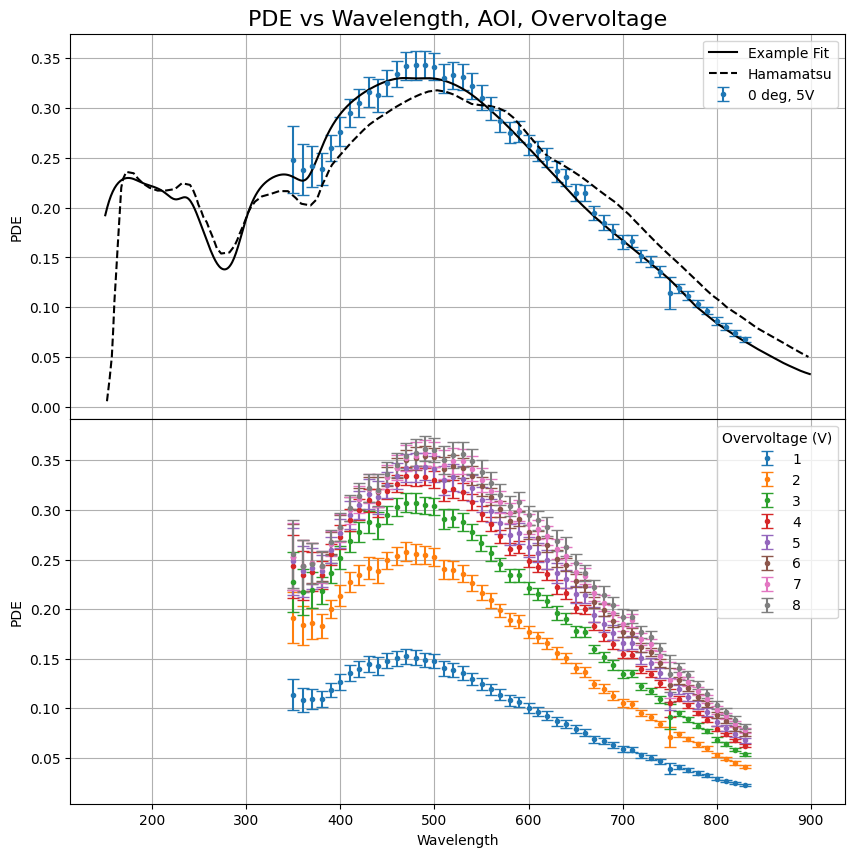

In [ ]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))
print("data Angles:", data_angles)
print("Data voltages:", data_voltages)

for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 5)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f} deg, 5V", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",yerr = "PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

# plotting some example curves
xExampleWlen = np.arange(150, 900, 1)
yExamplePDE = FF.PDE_allArgs_wlen(xExampleWlen, 0,
                             dp_star = 1.5, Xpn = 2000, 
                             dw_star = 12e3, pe=0.95, ph=0.3,
                             **fixedPars_Boring, **fixedPars_physics)
ax1.plot(xExampleWlen, yExamplePDE, label = "Example Fit", color = "black", linestyle = "-")

# hamamatsu curves
hamX, hamY = ODL.Load_Ham_data()
ax1.plot(hamX, hamY, label = "Hamamatsu", color = "black", linestyle = "--")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
ax1.legend()
plt.subplots_adjust(hspace=0)
plt.show()

In [ ]:
# ## timing
# copyDict = fixedPars_Boring.copy()
# copyDict["smoothSigma"] = None


# starTime = time.time()
# for i in range(int(1e4)):
#     FF.PDE_allArgs_wlen(175, 0, dp_star = 1.5, Xpn = 2000, dw_star = 12e3, pe=0.95, ph=0.3, **copyDict, **fixedPars_physics)
# endTime = time.time()
# callTime = (endTime - starTime)/1e4
# print("Time for 1 call:", callTime*1e6, " us")

---
### UV high V Fitting
No nested/nuisance pars are required here  
Global float: 
* float $dp^*$, use non parametrized Pe

In [40]:
 ##-- Buiding A1 dataset --##
UVLim = 420
# dataset 0A
v_0A = data_voltages[-1]
angle_0A = data_angles[0]

# temporary datasets. can include second high voltage if desired
dfA_t1 = df[(df['Overvoltage'] == data_voltages[-1]) & (df['Wavelength'] < UVLim)]

fullError = quadErrors(dfA_t1['PDE'].values, dfA_t1['PDE_error'].values, sys1.diodeError, getClosestNCAError(v_0A))
data_UV_V = [
    {"wlen":np.array(dfA_t1['Wavelength'].values), "yVals": dfA_t1['PDE'], 
     "yErrs": fullError, "theta1": angle_0A}]

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")
# print("data_UV_V[0]:", data_UV_V[0])


voltage wanted: 8 V
angle wanted: 0 deg


In [ ]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_A_UV = {**fixedPars_all, "Xpn": 2e3, "dw_star":10e3, "ph":0.0, "pe":peSat}

floatPars_A_UV = {"dp_star": 1.5,}
floatBounds_A_UV = {"dp_star": (0.01, 14)}

floatPars_B_UV = {"dp_star": 10, "Pdiff": 0.5}
floatBounds_B_UV = {"dp_star": (0.1, 200), "Pdiff": (0.0, 1.1)}

if fitFlag == "floatPsat":
    fixedPars_A_UV.pop("pe")
    floatPars_A_UV["pe"] = peSat
    floatBounds_A_UV["pe"] = (0.0, 1.1)
    
elif fitFlag == "floatFF":
    fixedPars_A_UV.pop("FF")
    floatPars_A_UV["FF"] = FF1
    floatBounds_A_UV["FF"] = (0.0, 1.1)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window']


In [ ]:
print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=FF.PDE_allArgs_wlen)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_V, FF.PDE_allArgs_wlen), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_V, functionToFit=FF.PDE_allArgs_wlen, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)

resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

#### diffusion fit ####
if fitFlag == "normal" and fitOpt == "diff":
    xoB_UV, xoB_UV_Names = SS.BuildX0(floatDict=floatPars_B_UV, functionToFit=FF.PDE_allArgs_halfBox)
    print("------ Case BE-UV Fit ------")
    SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_halfBox, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_B_UV,
                                    dBounds=floatBounds_B_UV, yNames=("yVals", "yErrs"), verbose=False)
    result_B_UV = iminuit.minimize(SS.GenericResiduals, x0=xoB_UV, args=(fixedPars_A_UV, data_UV_V, FF.PDE_allArgs_halfBox), method='migrad')

    SS.GenericResiduals(x0=result_B_UV.x, dataObj=data_UV_V, functionToFit=FF.PDE_allArgs_halfBox, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
    # print(result_B_UV)
    print("chi2 score-ish:", result_B_UV.fun)

    resDict_B_UV = SS.GetResDict(result_B_UV, xoB_UV_Names)
    resDictErrors_B_UV = SS.GetResErrorDict(result_B_UV, xoB_UV_Names)
    print(resDict_B_UV)
    print("errors:", resDictErrors_B_UV)

------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 7.944087682627471
{'dp_star': 2.3168}
errors: {'dp_star': 0.6699}
------ Case BE-UV Fit ------
chi2 score-ish: 0.5060669047403603
{'dp_star': 137.3437, 'Pdiff': 0.8712}
errors: {'dp_star': 99.121, 'Pdiff': 0.0356}


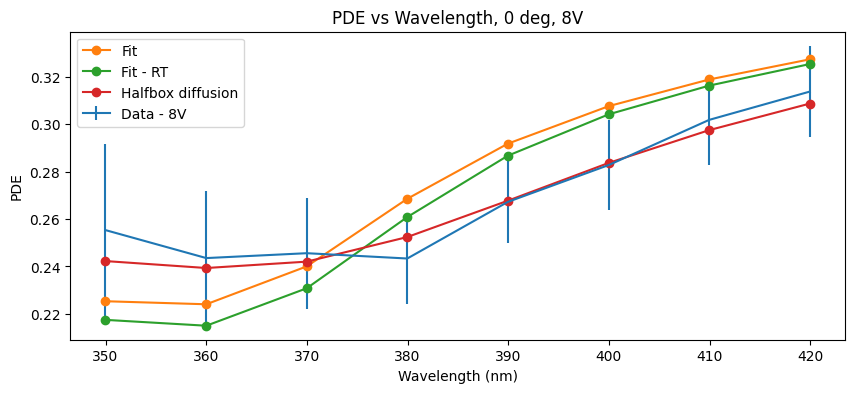

In [ ]:
figure = plt.figure(figsize=(10, 4))
## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_A_UV, **fixedPars_A_UV)

# plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")

# data
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data - 8V")

# fit
yFit = FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit", marker="o")

# fit no smearing
toPlotModified = fixedPars_A_UV.copy()
toPlotModified['Temperature'] = 300
# toPlotModified['dp_star'] = 0.5
# resDict_A_UV['dp_star'] = 0.5
yTest_rt=FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **toPlotModified)
plt.plot(data_UV_V[0]["wlen"], yTest_rt, label="Fit - RT", marker="o")

## halfbox fit
if fitFlag == "normal" and fitOpt == "diff":
    hbDict = {**resDict_B_UV, **fixedPars_A_UV}
    hbDict["dp_star"] = 150
    pde_hb = FF.PDE_allArgs_halfBox(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **hbDict)
    plt.plot(data_UV_V[0]["wlen"], pde_hb, label="Halfbox diffusion", marker="o")

plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.title("PDE vs Wavelength, 0 deg, 8V")
plt.legend()
plt.show()

In [44]:
# ## some kind of measured quantum yield
# yPDE_data = data_UV_V[0]["yVals"]
# xPDE = data_UV_V[0]["wlen"]
# yTransmission = PhotonInfo(wlen = xPDE).T_total_windowAndOxide(20)

# yData_internal = yPDE_data / yTransmission / FF1
# xAbsorption = PhotonInfo(wlen = xPDE).muSi

# plt.plot(1/xAbsorption, yData_internal, marker = "o")

---
---
### UV all V Fitting
No nested/nuisance pars are required here  
Global float: 
* float $dp^*$
* parametrized Pe

In [45]:
##-- Buiding A1 dataset --##
v_0A = data_voltages[-1]
angle_0A = data_angles[0]
data_UV1 = []

# temporary datasets. can include second high voltage if desired
for volt in data_voltages[1:]:
    dfA_uv_all = df[(df['Overvoltage'] == volt) & (df['Wavelength'] < UVLim)]
    
    
    oneD_dict = {"wlen":dfA_uv_all['Wavelength'].values, "yVals": dfA_uv_all['PDE'], "yErrs": dfA_uv_all['PDE_error'], "theta1": angle_0A, "voltage": volt}
    data_UV1.append(oneD_dict)

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")

# SS.CheckDataSetKey_consistent(data_UV_all, True);

voltage wanted: 8 V
angle wanted: 0 deg


In [46]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_UV = {**fixedPars_Boring, **fixedPars_physics, "Xpn": 2.0e3, "dw_star":10e3, "Vh":1, "Ah":0.0, "Ae":peSat}

floatPars_UV = {"dp_star": 1.5, "Ve":1.8}
floatBounds_UV = {"dp_star": (0.01, 5), "Ve": (0, 4)}
# SS.AddNonesToDict(dAddTo=floatBounds_UV, dRef=floatPars_UV)

floatPars_B_UV = {"dp_star": 10, "Pdiff": 0.5, "Ve":1.8}
floatBounds_B_UV = {"dp_star": (0.1, 200), "Pdiff": (0.0, 1.1), "Ve": (0, 4)}

if fitFlag == "floatPsat":
    fixedPars_UV.pop("Ae")
    floatPars_UV["Ae"] = peSat
    floatBounds_UV["Ae"] = (0.0, 1.1)
elif fitFlag == "floatFF":
    fixedPars_UV.pop("FF")
    floatPars_UV["FF"] = FF1
    floatBounds_UV["FF"] = (0.0, 1.1)

print("------ Case UV-all setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_UV1, dFixed=fixedPars_UV, dFloat=floatPars_UV,
                                   dBounds=floatBounds_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case UV-all Fit ------")
result_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_UV, data_UV1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_UV.x, dataObj=data_UV1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_UV)
print("chi2 score-ish:", result_UV.fun)

resDict_UV = SS.GetResDict(result_UV, xoAE_UV_Names)
resDictErrors_UV = SS.GetResErrorDict(result_UV, xoAE_UV_Names)
print(resDict_UV)
print("errors:", resDictErrors_UV)

if fitFlag == "normal" and fitOpt == "diff":
    xoB_UV, xoB_UV_Names = SS.BuildX0(floatDict=floatPars_B_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox)
    print("------ Case BE-UV Fit ------")
    SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized_halfBox, dataObj=data_UV1, dFixed=fixedPars_UV, dFloat=floatPars_B_UV,
                                    dBounds=floatBounds_B_UV, yNames=("yVals", "yErrs"), verbose=False)
    result_B_UV = iminuit.minimize(SS.GenericResiduals, x0=xoB_UV, args=(fixedPars_UV, data_UV1, FF.PDE_allArgs_wlen_parametrized_halfBox), method='migrad')

    SS.GenericResiduals(x0=result_B_UV.x, dataObj=data_UV1, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox, fixedArgs_dict=fixedPars_UV, verbose=False, yNames=("yVals", "yErrs"))
    # print(result_B_UV)
    print("chi2 score-ish:", result_B_UV.fun)
    resDict_Bdiff_UV = SS.GetResDict(result_B_UV, xoB_UV_Names)
    resDictErrors_Bdiff_UV = SS.GetResErrorDict(result_B_UV, xoB_UV_Names)
    print(resDict_Bdiff_UV)
    print("errors:", resDictErrors_Bdiff_UV)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window']
------ Case UV-all setup ------
------ Case UV-all Fit ------
chi2 score-ish: 49.089261483163206
{'dp_star': 1.3979, 'Ve': 1.7599}
errors: {'dp_star': 0.2567, 'Ve': 0.0405}
------ Case BE-UV Fit ------
chi2 score-ish: 6.253381347317355
{'dp_star': 118.7224, 'Ve': 1.4266, 'Pdiff': 0.8753}
errors: {'dp_star': 27.0267, 'Ve': 0.0498, 'Pdiff': 0.013}


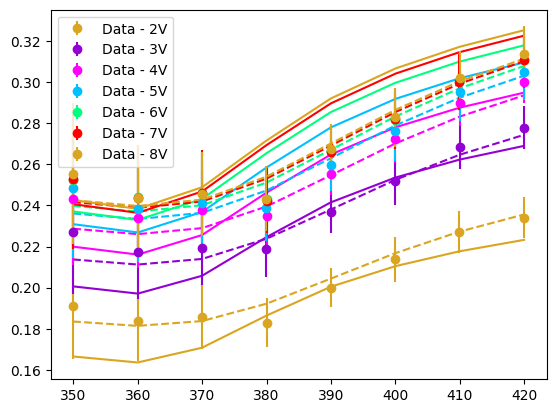

In [47]:
## plotting ##
ms.ResetColorCycle()
for oneD in data_UV1:
    col = ms.GetNextColor()
    plt.errorbar(oneD["wlen"], oneD["yVals"], yerr=oneD["yErrs"], label=f"Data - {oneD['voltage']:0.0f}V", marker = "o", linestyle = "None", color = col)

    # fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_UV, **fixedPars_UV)
    plt.plot(oneD["wlen"], yFit,color = col)
    
    # diff fit
    if fitFlag == "normal" and fitOpt == "diff":
        yFitDiff = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_Bdiff_UV, **fixedPars_UV)
        plt.plot(oneD["wlen"], yFitDiff, color = col, linestyle = "--")

plt.legend()
plt.show()

In [48]:
# ## some kind of measured quantum yield
# yPDE_data = data_UV_V[0]["yVals"]
# xPDE = data_UV_V[0]["wlen"]
# yTransmission = PhotonInfo(wlen = xPDE).T_total_windowAndOxide(20)

# yData_internal = yPDE_data / yTransmission / FF1
# xAbsorption = PhotonInfo(wlen = xPDE).muSi

# plt.plot(1/xAbsorption, yData_internal, marker = "o")

---
### Sequential fitting - all wavelengths

Now including all wavelengths, keeping values from front of junction

In [51]:
data_ir1 = []
for V in data_voltages[1:]:
    dfA_t1 = df[(df['Overvoltage'] == V)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'].values,
                 "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error'],
                 "theta1": angle_0A, "voltage": V}

    # print(dfA_t1['PDE'].values[0:10])
    data_ir1.append(oneD_dict)

In [52]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_ir = {**fixedPars_Boring, **fixedPars_physics}
fixedPars_ir = {**fixedPars_ir, **resDict_UV, "Ah": 1, "Ae":peSat} # this isn't a typo

floatPars_ir = {"Xpn": 2.0e3, "dw_star":12e3, "Vh":17}
floatBounds_ir = {"Xpn": (0.0, 4e3), "dw_star": (4e3, 20e3), "Vh": (0, 30)}
print(fixedPars_ir)
print(floatPars_ir)
# SS.AddNonesToDict(dAddTo=floatBounds_ir, dRef=floatPars_ir)

if fitFlag == "floatPsat":
    fixedPars_ir.pop("Ae")
    floatPars_ir["Ae"] = peSat
    floatBounds_ir["Ae"] = (0.0, 1.1)
elif fitFlag == "floatFF":
    fixedPars_ir.pop("FF")
    floatPars_ir["FF"] = FF1
    floatBounds_ir["FF"] = (0.0, 1.1)

print("------ Case IR-all setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_ir1, dFixed=fixedPars_ir, dFloat=floatPars_ir,
                                   dBounds=floatBounds_ir, yNames=("yVals", "yErrs"), verbose=False)
xoAE_ir, xoAE_ir_Names = SS.BuildX0(floatDict=floatPars_ir, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_ir, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case IR-all Fit ------")
result_ir = iminuit.minimize(SS.GenericResiduals, x0=xoAE_ir, bounds = xABounds, args=(fixedPars_ir, data_ir1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_ir.x, dataObj=data_ir1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_ir, verbose=False, yNames=("yVals", "yErrs"))
# print(result_ir)
print("chi2 score-ish:", result_ir.fun)

resDict_ir = SS.GetResDict(result_ir, xoAE_ir_Names)
resDictErrors_ir = SS.GetResErrorDict(result_ir, xoAE_ir_Names)
print(resDict_ir)
print("errors:", resDictErrors_ir)


if fitFlag == "normal" and fitOpt == "diff":
    fixedPars_Bdiff_ir = {**fixedPars_ir, **resDict_Bdiff_UV}
    SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized_halfBox, dataObj=data_ir1, dFixed=fixedPars_Bdiff_ir, dFloat=floatPars_ir,
                                   dBounds=floatBounds_ir, yNames=("yVals", "yErrs"), verbose=False)

    print("------ Case IR Bdiffuse Fit ------")
    result_Bdiff_ir = iminuit.minimize(SS.GenericResiduals, x0=xoAE_ir, bounds = xABounds, args=(fixedPars_Bdiff_ir, data_ir1, FF.PDE_allArgs_wlen_parametrized_halfBox), method='migrad')
    SS.GenericResiduals(x0=result_ir.x, dataObj=data_ir1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_ir, verbose=False, yNames=("yVals", "yErrs"))
    # print(result_ir)
    print("chi2 score-ish:", result_Bdiff_ir.fun)

    resDict_Bdiff_ir = SS.GetResDict(result_Bdiff_ir, xoAE_ir_Names)
    resDictErrors_Bdiff_ir = SS.GetResErrorDict(result_Bdiff_ir, xoAE_ir_Names)
    print(resDict_Bdiff_ir)
    print("errors:", resDictErrors_Bdiff_ir)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window']
{'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True, 'FF': 0.6, 'tOxide': 16.8, 'dp_star': 1.3979, 'Ve': 1.7599, 'Ah': 1, 'Ae': 1.0}
{'Xpn': 2000.0, 'dw_star': 12000.0, 'Vh': 17}
------ Case IR-all setup ------
------ Case IR-all Fit ------
chi2 score-ish: 287.1202698367918
{'Xpn': 2552.1147, 'dw_star': 15663.605, 'Vh': 20.4854}
errors: {'Xpn': 29.1338, 'dw_star': 532.7234, 'Vh': 0.7874}
------ Case IR Bdiffuse Fit ------
chi2 score-ish: 265.41417348839525
{'Xpn': 2025.4272, 'dw_star': 11826.7441, 'Vh': 13.4168}
errors: {'Xpn': 27.9494, 'dw_star': 322.3662, 'Vh': 0.4712}


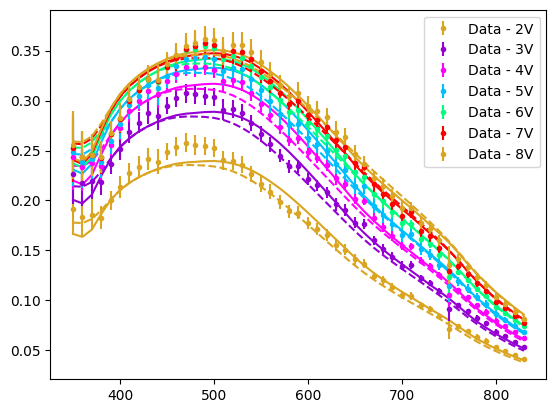

In [53]:
## plotting ##
ms.ResetColorCycle()
for oneD in data_ir1:
    col = ms.GetNextColor()
    plt.errorbar(oneD["wlen"], oneD["yVals"], yerr=oneD["yErrs"], label=f"Data - {oneD['voltage']:0.0f}V", 
                 marker = "o", markersize = 3, linestyle = "None", color = col)

    # fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_ir, **fixedPars_ir)
    plt.plot(oneD["wlen"], yFit,color = col)
    
    # diff fit
    if fitFlag == "normal" and fitOpt == "diff":
        yFitDiff = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_Bdiff_ir, **fixedPars_ir)
        plt.plot(oneD["wlen"], yFitDiff, color = col, linestyle = "--")

# plt.xlim(340, 450)
plt.legend()
plt.show()

---
## Global fit, parametrized Pe, Ph
* float global: $X_{pn}$, $dw^*$, $dp^*$, $V_e$, $V_h$, $Ae$
* no nested fitting, not floating individually: $P_e$, $P_h$

data is an array of dicts, each dict is a dataset. Not using array of OneNuisanceDataSet

In [56]:
##-- Buiding Vis all dataset --##
data_global1 = []
for V in data_voltages[1:]:
    dfA_t1 = df[(df['Overvoltage'] == V)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'].values,
                 "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error'],
                 "theta1": angle_0A, "voltage": V}

    # print(dfA_t1['PDE'].values[0:10])
    data_global1.append(oneD_dict)

In [57]:
def KeysMissingInDictFromArrayOfStrings(dict1, array1):
    return [key for key in array1 if key not in dict1]
# global fixed
names = SS.GetNames(FF.PDE_allArgs_wlen_parametrized)
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_global1 = {**fixedPars_Boring, **fixedPars_physics, **fixedPars_parametrized}
print("fixed inputs:", fixedPars_global1)

# print("missing keys in data:", KeysMissingInDictFromArrayOfStrings(names, fixedPars_global1))

floatPars_global1 = {"dp_star": 1., "Xpn": 2.5e3, "dw_star": 12e3, "Ve": 1.5, "Vh": 18}
floatParBounds_global1 = { "dp_star": (0.01, 10), "Xpn": (0.8e3, 4e3), "dw_star": (4e3, 20e3), "Ve": (0.5, 4), "Vh": (4, 50)}

if fitFlag == "floatPsat":
    fixedPars_global1.pop("Ae")
    floatPars_global1["Ae"] = peSat
    floatParBounds_global1["Ae"] = (0.0, 1.1)
    print("-----\nfloating Ae\n------")
    
elif fitFlag == "floatFF":
    fixedPars_global1.pop("FF")
    floatPars_global1["FF"] = FF1
    floatParBounds_global1["FF"] = (0.0, 1.1)
    print("-----\nfloating FF\n------")

x0_global1, x0_global1_Names = SS.BuildX0(floatDict=floatPars_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case global1 setup ------")
check = SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_global1, dFixed=fixedPars_global1, dFloat=floatPars_global1,
                                   dBounds=floatParBounds_global1, yNames=("yVals", "yErrs"), verbose=False)
print("check all good:", check)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window']
fixed inputs: {'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True, 'FF': 0.6, 'tOxide': 16.8, 'Ae': 1.0, 'Ah': 1.0}
------ Case global1 setup ------
check all good: True


In [58]:
print("------ Case global1 fit ------")
starTime = time.time()
result_global1 = iminuit.minimize(SS.GenericResiduals, x0=x0_global1, bounds = x0_global1_bounds, args=(fixedPars_global1, data_global1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_global1.x, dataObj=data_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_global1, verbose=False, yNames=("yVals", "yErrs"))
print("\nDone fit!, time taken:", time.time()-starTime)
print("chi2 score-ish:", result_global1.fun)

resDict_global1 = SS.GetResDict(result_global1, x0_global1_Names)
resDictErrors_global1 = SS.GetResErrorDict(result_global1, x0_global1_Names)
print("values:", resDict_global1)
print("errors:", resDictErrors_global1)

------ Case global1 fit ------

Done fit!, time taken: 1.7696759700775146
chi2 score-ish: 269.2976794568737
values: {'dp_star': 1.6726, 'Xpn': 2343.0643, 'dw_star': 14120.5658, 'Ve': 1.65, 'Vh': 17.4488}
errors: {'dp_star': 0.2314, 'Xpn': 45.4313, 'dw_star': 499.3134, 'Ve': 0.0187, 'Vh': 0.7951}


In [59]:
if fitFlag == "normal" and fitOpt == "diff":
    floatPars_Bdiff_global1 = {"dp_star": 100, "Xpn": 2.5e3, "dw_star": 12e3, "Ve": 1.5, "Vh": 20, "Pdiff": 0.9}
    floatParBounds_Bdiff_global1 = {**floatParBounds_global1, "dp_star": (1, 200), "Pdiff": (0.0, 1.1)}

    x0_Bdiff_global1, x0_Bdiff_global1_Names = SS.BuildX0(floatDict=floatPars_Bdiff_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox)
    x0_Bdiff_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Bdiff_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox)

    print("------ Case global1, diffusion setup ------")
    check = SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized_halfBox, dataObj=data_global1, dFixed=fixedPars_global1, dFloat=floatPars_Bdiff_global1,
                                    dBounds=floatParBounds_Bdiff_global1, yNames=("yVals", "yErrs"), verbose=False)
    print("check all good:", check)

------ Case global1, diffusion setup ------
check all good: True


In [60]:
if fitFlag == "normal" and fitOpt == "diff":
    print("------ Case global1, diffusion fit ------")
    starTime = time.time()
    result_Bdiff_global1 = iminuit.minimize(SS.GenericResiduals, x0=x0_Bdiff_global1, bounds = x0_Bdiff_global1_bounds, args=(fixedPars_global1, data_global1, FF.PDE_allArgs_wlen_parametrized_halfBox), method='migrad')
    SS.GenericResiduals(x0=result_Bdiff_global1.x, dataObj=data_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox, fixedArgs_dict=fixedPars_global1, verbose=False, yNames=("yVals", "yErrs"))
    print("\nDone fit!, time taken:", time.time()-starTime)
    print("chi2 score-ish:", result_Bdiff_global1.fun)

    resDict_Bdiff_global1 = SS.GetResDict(result_Bdiff_global1, x0_Bdiff_global1_Names)
    resDictErrors_Bdiff_global1 = SS.GetResErrorDict(result_Bdiff_global1, x0_Bdiff_global1_Names)
    print("values:", resDict_Bdiff_global1)
    print("errors:", resDictErrors_Bdiff_global1)

------ Case global1, diffusion fit ------

Done fit!, time taken: 2.5973191261291504
chi2 score-ish: 232.58068345610172
values: {'dp_star': 49.1157, 'Xpn': 2244.3205, 'dw_star': 13286.5728, 'Ve': 1.5766, 'Vh': 16.0903, 'Pdiff': 0.8746}
errors: {'dp_star': 10.9773, 'Xpn': 47.2533, 'dw_star': 469.879, 'Ve': 0.0215, 'Vh': 0.7576, 'Pdiff': 0.0163}


{'dp_star': 1.6726, 'Xpn': 2343.0643, 'dw_star': 14120.5658, 'Ve': 1.65, 'Vh': 17.4488, 'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True, 'FF': 0.6, 'tOxide': 16.8, 'Ae': 1.0, 'Ah': 1.0}


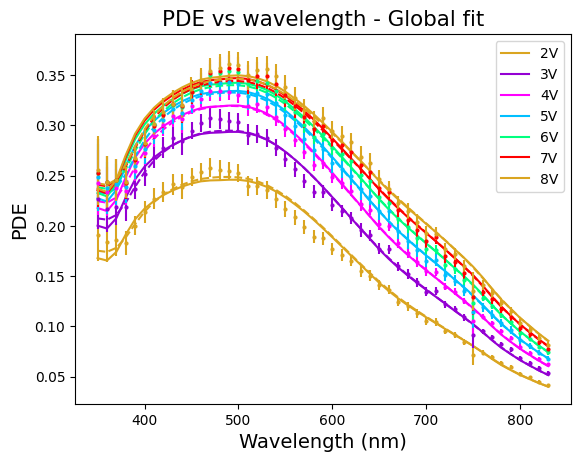

In [61]:
dict_final_global1 = {**resDict_global1, **fixedPars_global1}
print(dict_final_global1)
ms.ResetColorCycle()
for dc in data_global1:
    xwlen = dc["wlen"]
    theta = dc["theta1"]
    y = dc["yVals"]
    yErrs = dc["yErrs"]
    voltage = dc["voltage"]
    # if voltage != 6:
    #     continue
    # print(dc.keys())
    
    col = ms.GetNextColor()
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
    # copyDict = dict_final_global1.copy()
    # copyDict["Vh"] = 13
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1=theta, voltage = voltage, **dict_final_global1)
    plt.plot(xwlen, yFit, color = col, label = f"{voltage}V")

    if fitFlag == "normal" and fitOpt == "diff":
        yFitDiff = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen=xwlen, theta1=theta, voltage = voltage, **resDict_Bdiff_global1, **fixedPars_global1)
        plt.plot(xwlen, yFitDiff, color = col, linestyle = "--")

# plt.title("global fit")
fsize = 14
plt.xlabel("Wavelength (nm)", fontsize = fsize)
plt.ylabel("PDE", fontsize = fsize)
plt.title("PDE vs wavelength - Global fit", fontsize = 1.1 * fsize)
plt.legend()
plt.show()

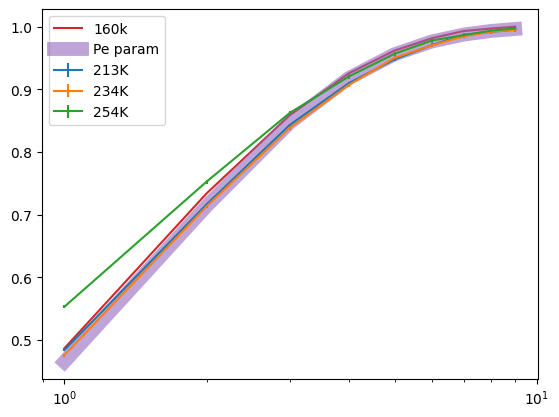

In [62]:
## more PE data from harry (different temps)
# Overvoltage values (in volts)

## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]
plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, label = "213K")

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]
plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, label = "234K")

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]
plt.errorbar(overvoltage_254k, pa_254k, pa_error_254k, label = "254K")

plt.semilogx(harryVoltagePE, harryPe, label="160k")

plt.semilogx(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=1.6), linewidth = 10, alpha=0.6, label = "Pe param")

# plt.xlim(4, 8)
# plt.ylim(0.9, 1)
plt.legend()
plt.show()

[-0.03180156 -0.03123841 -0.02088961 -0.01402917 -0.010146   -0.00804398
 -0.00743771 -0.00494325]


[]

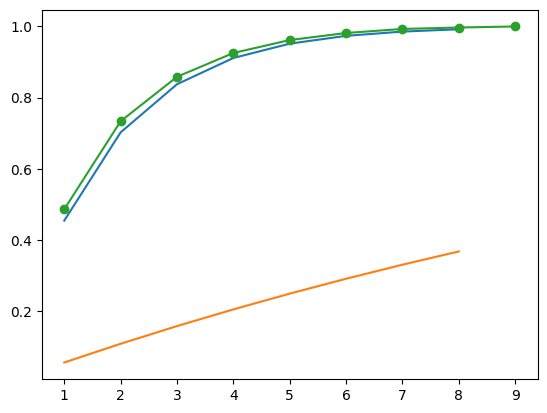

In [63]:
fitPeVals = ME.Pcar_parametrized(data_voltages, Vc=resDict_global1["Ve"])
plt.plot(data_voltages, fitPeVals)
plt.plot(data_voltages, ME.Pcar_parametrized(data_voltages, Vc=resDict_global1["Vh"], A=1.0), label = "Ph")

plt.plot(harryVoltagePE, harryPe, marker = "o")

print(fitPeVals - harryPe[:-1])
plt.plot()

In [64]:
import json

# Combine the dictionaries
combined_dict = {key: [resDict_global1[key], resDictErrors_global1[key]] for key in resDict_global1}

# Convert the combined dictionary to JSON with compact arrays
json_table = json.dumps(combined_dict, indent=None, separators=(',', ': '), sort_keys=False)

# Manually format the JSON string to add a newline after each key-value pair
formatted_json_table = json_table.replace('],', '],\n')
# formatted_json_table = json_table.replace('{', '{\n')
# formatted_json_table = json_table.replace('}', '}\n')

# Print the formatted JSON table
print(formatted_json_table)

{"dp_star": [1.6726,0.2314],
"Xpn": [2343.0643,45.4313],
"dw_star": [14120.5658,499.3134],
"Ve": [1.65,0.0187],
"Vh": [17.4488,0.7951]}


---
## Non-parametrized Pe, Ph (nested float)

* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_e$, $P_h$

next try floatin Xpn for each voltage

In [65]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_global_nested = []

for V in data_voltages[:]:
    df_nested = df[(df['Overvoltage'] == V)]
    oneD_dict = {"wlen":df_nested['Wavelength'].values, "yVals": df_nested['PDE'].values, "yErrs": df_nested['PDE_error'].values, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fullFloat = {"pe": ME.Pcar_parametrized(V, Vc=resDict_global1["Ve"]),
                 "ph": ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"])}
    fullBounds = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat.copy(), nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global_nested.append(odFull_global)

[2 3 4 5 6 7 8]


In [ ]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_global_nested = {**fixedPars_physics, **fixedPars_Boring}
print("fixed inputs:", fixedPars_global_nested)
print("\nfixed inputs:", fixedPars_global_nested)

floatPars_global_nested = {"dp_star":0.3, "Xpn": 2e3, "dw_star": 13e3}
floatParBounds_global_nested = {"dp_star":(0.01, 15), "Xpn": (0.2e3, 5e3), "dw_star": (5e3, 20e3)}

x0_global_nested, x0_global_nested_Names = SS.BuildX0(floatDict=floatPars_global_nested, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global_nested, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case global_nested setup ------")

# dd = data_global_nested[0].oneDData[0]
# print(data_global_nested[0].mDict_nuisFloat)
# FF.PDE_allArgs_wlen(wlen=dd["wlen"], theta1=dd["theta1"], **fixedPars_global_nested, **floatPars_global_nested, **data_global_nested[0].mDict_nuisFloat)
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested, globalFixed=fixedPars_global_nested, dataPackage=data_global_nested,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

# for oneD in data_global_nested:
#     print(oneD.extraV)
#     print(oneD.mDict_nuisFloat)
#     plt.plot(oneD.oneDData[0]["wlen"], oneD.oneDData[0]["yVals"], label = f"{oneD.extraV}V", marker = "o", color="red", linestyle = "")
#     print(len(oneD.oneDData[0]["wlen"]))
#     # print(oneD.nuisanceBounds)
#     print(oneD.resultDict.values())

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window']
fixed inputs: {'FF': 0.6, 'tOxide': 16.8, 'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True}

fixed inputs: {'FF': 0.6, 'tOxide': 16.8, 'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True}
------ Case global_nested setup ------


271.4487322267228

In [ ]:
starTime = time.time()
globalFit_global_nested = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested, bounds = x0_global_nested_bounds,
                                        args=(fixedPars_global_nested, data_global_nested, FF.PDE_allArgs_wlen), method='migrad')

SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global_nested.x, globalFixed=fixedPars_global_nested, dataPackage=data_global_nested,
                                    functionToFit=FF.PDE_allArgs_wlen, verbose=False)
print("Done fit!, time taken:", time.time()-starTime)

Done fit!, time taken: 37.254903078079224


In [68]:
# print(globalFit_Visall_S)
print("score:", globalFit_global_nested.fun)
resDict_global_nested = SS.GetResDict(globalFit_global_nested, x0_global_nested_Names)
resDictError_global_nested = SS.GetResErrorDict(globalFit_global_nested, x0_global_nested_Names)
print(resDict_global_nested)
print(resDictError_global_nested)

phFull_dict_global_nested = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_nested}
peFull_dict_global_nested = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_nested}

print("pe:", peFull_dict_global_nested)
print("ph:", phFull_dict_global_nested)

score: 233.12418421109226
{'dp_star': 1.7945, 'Xpn': 2011.3118, 'dw_star': 12119.237}
{'dp_star': 0.2373, 'Xpn': 46.9705, 'dw_star': 370.7295}
pe: {1: (0.4124, 0.0033), 2: (0.7047, 0.0042), 3: (0.8499, 0.0043), 4: (0.93, 0.0042), 5: (0.9553, 0.0062), 6: (0.9862, 0.0049), 7: (0.991, 0.0061), 8: (1.0018, 0.006)}
ph: {1: (0.0748, 0.0023), 2: (0.1526, 0.003), 3: (0.2191, 0.0032), 4: (0.2704, 0.0032), 5: (0.3119, 0.0051), 6: (0.3512, 0.004), 7: (0.3862, 0.0052), 8: (0.4161, 0.0053)}


{'dp_star': 1.7945, 'Xpn': 2011.3118, 'dw_star': 12119.237, 'FF': 0.6, 'tOxide': 16.8, 'Temperature': 160, 'dh': None, 'smoothSigma': 11.88, 'quantum': False, 'window': True}


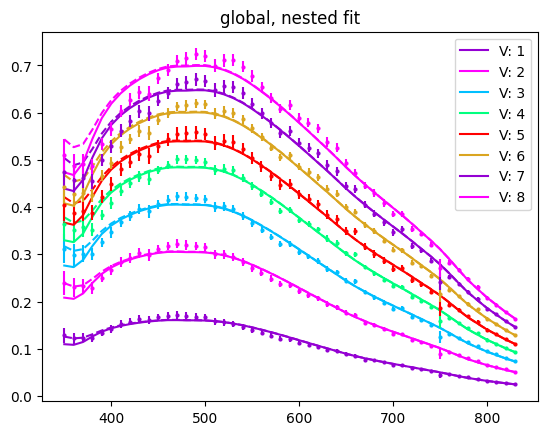

In [ ]:
dict_final_global_nested = {**resDict_global_nested, **fixedPars_global_nested}
print(dict_final_global_nested)

for dc in data_global_nested:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localScaling = 1 + 1*voltage / 8
    localPe = peFull_dict_global_nested[voltage][0]
    localPh = phFull_dict_global_nested[voltage][0]
    pArgs = {"pe": localPe, "ph": localPh}
    pArgs = dc.resultDict
    
    col = ms.GetNextColor()
    yFit = localScaling * FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global_nested, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    
    copyDict = dict_final_global_nested.copy()
    copyDict["dp_star"] = 0.3
    yFit_short = localScaling* FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **copyDict, **pArgs)
    plt.plot(xwlen, yFit_short, color = col, linestyle = "--")
    
    plt.errorbar(xwlen, localScaling*y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

# plt.xlim(340, 450)
plt.title("global, nested fit")
plt.legend()
plt.show()

---
### Plotting all ATP curves

In [70]:
ms.ResetColorCycle()

yph_global_nested = [phFull_dict_global_nested[voltage][0] for voltage in data_voltages]
yphErr_global_nested = [phFull_dict_global_nested[voltage][1] for voltage in data_voltages]

ype_global_nested = [peFull_dict_global_nested[voltage][0] for voltage in data_voltages]
ypeErr_global_nested = [peFull_dict_global_nested[voltage][1] for voltage in data_voltages]

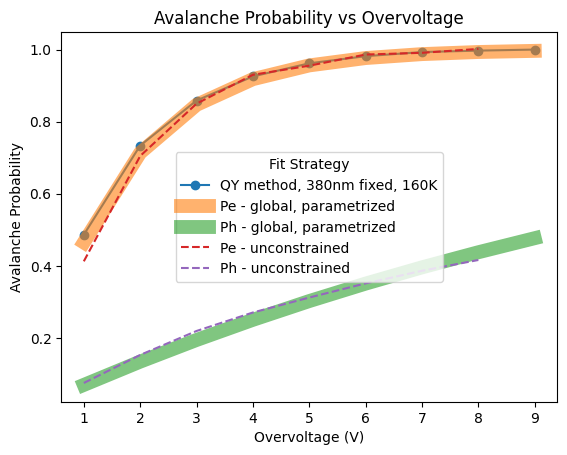

In [71]:

## more PE data from harry (different temps)
# Overvoltage values (in volts)

## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]

# other temps
# plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, marker = "o", label = "213K")
# plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, marker = "o", label = "234K")
# plt.errorbar(overvoltage_254k, pa_254k, pa_error_254k, marker = "o", label = "254K")

plt.plot(harryVoltagePE, harryPe, marker = "o", label="QY method, 380nm fixed, 160K")

plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=1.6), linewidth = 10, alpha=0.6, label = "Pe - global, parametrized")
plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=13.9), linewidth = 10, alpha=0.6, label = "Ph - global, parametrized")

plt.plot(data_voltages, ype_global_nested, linestyle = "--", label = "Pe - unconstrained")
plt.plot(data_voltages, yph_global_nested, linestyle = "--", label = "Ph - unconstrained")

# plt.xscale("log")

plt.ylabel("Avalanche Probability")
plt.xlabel("Overvoltage (V)")
plt.title("Avalanche Probability vs Overvoltage")
# plt.xlim(4, 8)
# plt.ylim(0.9, 1)

plt.legend(title = "Fit Strategy")
plt.show()

---
### Summarizing the fits


In [72]:
print("fit options:",   fitFlag)
print("UV high V:",     resDict_A_UV, result_A_UV.fun)
print("UV all:",        resDict_UV, result_UV.fun)
print("IR :",           resDict_ir, result_ir.fun)
print("global, par:", resDict_global1, result_global1.fun)
print("global, free P", resDict_global_nested, globalFit_global_nested.fun)
print("pe:", ype_global_nested[-1])

if fitFlag == "normal" and fitOpt == "diff":
    print("\n\nUV B-diff:", resDict_Bdiff_UV, result_B_UV.fun)
    print("IR B-diff:", resDict_Bdiff_ir, result_Bdiff_ir.fun)
    print("global, diff:", resDict_Bdiff_global1, result_Bdiff_global1.fun)

fit options: normal
UV high V: {'dp_star': 2.3168} 7.944087682627471
UV all: {'dp_star': 1.3979, 'Ve': 1.7599} 49.089261483163206
IR : {'Xpn': 2552.1147, 'dw_star': 15663.605, 'Vh': 20.4854} 287.1202698367918
global, par: {'dp_star': 1.6726, 'Xpn': 2343.0643, 'dw_star': 14120.5658, 'Ve': 1.65, 'Vh': 17.4488} 269.2976794568737
global, free P {'dp_star': 1.7945, 'Xpn': 2011.3118, 'dw_star': 12119.237} 233.12418421109226
pe: 1.0018


UV B-diff: {'dp_star': 118.7224, 'Ve': 1.4266, 'Pdiff': 0.8753} 6.253381347317355
IR B-diff: {'Xpn': 2025.4272, 'dw_star': 11826.7441, 'Vh': 13.4168} 265.41417348839525
global, diff: {'dp_star': 49.1157, 'Xpn': 2244.3205, 'dw_star': 13286.5728, 'Ve': 1.5766, 'Vh': 16.0903, 'Pdiff': 0.8746} 232.58068345610172


In [73]:
# xTest = np.arange(350, 800, 2)
# yTest = FF.PDE_allArgs_wlen_parametrized(xTest, theta1=0, voltage = 4, **resDict_global1, **fixedPars_Boring, **fixedPars_physics)

# yTest_diffuse = FF.PDE_allArgs_wlen_parametrized_halfBox(xTest, theta1=0, voltage = 4, **resDict_Bdiff_global1, **fixedPars_Boring, **fixedPars_physics)
# plt.plot(xTest, yTest, label = "Normal")

# pVals = [0.1, 0.7, 0.9, 1.0]
# for pd in pVals:
#     resDict_Bdiff_global1["Pdiff"] = pd
#     resDict_Bdiff_global1["dp_star"] = 800
#     yTest_diffuse = FF.PDE_allArgs_wlen_parametrized_halfBox(xTest, theta1=0, voltage = 6, **resDict_Bdiff_global1, **fixedPars_Boring, **fixedPars_physics)
#     # print(resDict_Bdiff_global1, fixedPars_Boring, fixedPars_physics)
#     plt.plot(xTest, yTest_diffuse, label = f"Pdiff: {pd}")

# plt.legend()
# # plt.plot(xTest, yTest_diffuse, label = "Diffuse")

---
## Nested, parametrized Pe, Ph, float Xpn

In [74]:
# ##-- Buiding Vis all dataset --##
# print(data_voltages[:])
# data_global_xpn = []

# for V in data_voltages[:]:
#     df_xpn = df[(df['Overvoltage'] == V)]
#     oneD_dict = {"wlen":df_xpn['Wavelength'].values, "yVals": df_xpn['PDE'].values, "yErrs": df_xpn['PDE_error'].values, "voltage":V, "theta1": angle_0A}
    
#     ## global dataset, float pe, ph
#     fullFloat = {"Xpn":2e3}
#     fullBounds = {"Xpn": (800, 4e3)}
    
#     odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat.copy(), nuisanceBounds=fullBounds,
#                                     nuisanceFixed={})
#     odFull_global.extraV = V
#     data_global_xpn.append(odFull_global)

In [ ]:
# # global fixed
# print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

# fixedPars_global_xpn = {"tOxide":ttGood, **fixedPars_physics, **fixedPars_parametrized, **fixedPars_Boring}
# print("fixed inputs:", fixedPars_global_xpn)

# floatPars_global_xpn = {"dp_star":resDict_global1["dp_star"], "dw_star": 13e3, "Ve":2, "Vh":20}
# floatParBounds_global_xpn = {"dp_star":(0.5, 15), "dw_star": (6e3, 20e3), "Ve": (0.1, 10), "Vh": (1, 50)}

# x0_global_xpn, x0_global_xpn_Names = SS.BuildX0(floatDict=floatPars_global_xpn, functionToFit=FF.PDE_allArgs_wlen_parametrized)
# x0_global_xpn_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global_xpn, functionToFit=FF.PDE_allArgs_wlen_parametrized)

# print("------ Case global_xpn setup ------")

# SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_xpn, globalFixed=fixedPars_global_xpn, dataPackage=data_global_xpn,
#                                functionToFit=FF.PDE_allArgs_wlen_parametrized, verbose=False)

# for oneD in data_global_xpn:
#     print(oneD.resultDict.values())

In [ ]:
# starTime = time.time()
# globalFit_global_xpn = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_xpn, bounds = x0_global_xpn_bounds,
#                                         args=(fixedPars_global_xpn, data_global_xpn, FF.PDE_allArgs_wlen_parametrized), method='migrad')

# SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global_xpn.x, globalFixed=fixedPars_global_xpn, dataPackage=data_global_xpn,
#                                     functionToFit=FF.PDE_allArgs_wlen_parametrized, verbose=True)
# print("Done fit!, time taken:", time.time()-starTime)

In [ ]:
# # print(globalFit_Visall_S)
# print("score:", globalFit_global_xpn.fun)
# resDict_global_xpn = SS.GetResDict(globalFit_global_xpn, x0_global_xpn_Names)
# resDictError_global_xpn = SS.GetResErrorDict(globalFit_global_xpn, x0_global_xpn_Names)
# print(resDict_global_xpn)
# print(resDictError_global_xpn)

# phFull_dict_global_xpn = {dc.extraV: (dc.resultDict["Xpn"], dc.resultErrorsDict["Xpn"]) for dc in data_global_xpn}

# print("xpn:", phFull_dict_global_xpn)

In [ ]:
# dict_final_global_xpn = {**resDict_global_xpn, **fixedPars_global_xpn}
# print(dict_final_global_xpn)
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), height_ratios=[3, 1])

# for dc in data_global_xpn:
#     oneD = dc.oneDData[0]
#     xwlen = oneD["wlen"]
#     y = oneD["yVals"]
#     yErrs = oneD["yErrs"]
    
#     voltage = dc.extraV
    
#     col = ms.GetNextColor()
    
#     yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1=oneD["theta1"], voltage = oneD["voltage"], **dict_final_global_xpn, **dc.resultDict)
#     ax1.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
#     ax1.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

# yxpn = [phFull_dict_global_xpn[key][0] for key in phFull_dict_global_xpn.keys()]
# yxpn_err = [phFull_dict_global_xpn[key][1] for key in phFull_dict_global_xpn.keys()]
# print(yxpn)
# ax2.errorbar(phFull_dict_global_xpn.keys(), yxpn, yxpn_err, label = "Xpn")
# ax1.set_title("global fit")
# ax1.legend()
# plt.show()